In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Cybersecurity_Breaches.csv")

In [4]:
df.drop(df.columns[0], axis=1, inplace=True)

In [5]:
df['Date_of_Breach'] = pd.to_datetime(df['Date_of_Breach'], errors = 'coerce')
df['breach_start'] = pd.to_datetime(df['breach_start'], errors = 'coerce')
df['breach_end'] = pd.to_datetime(df['breach_end'], errors = 'coerce')

In [6]:
df['Individuals_Affected'] = pd.to_numeric(df['Individuals_Affected'])

In [7]:
missing = df.isnull().sum()
print(missing)

Number                                0
Name_of_Covered_Entity                0
State                                 0
Business_Associate_Involved         784
Individuals_Affected                  0
Date_of_Breach                      146
Type_of_Breach                        0
Location_of_Breached_Information      0
Date_Posted_or_Updated                0
Summary                             913
breach_start                          0
breach_end                          910
year                                  0
dtype: int64


In [8]:
clean_df = df.dropna(subset = ['year', 'Type_of_Breach', 'State', 'Individuals_Affected'])

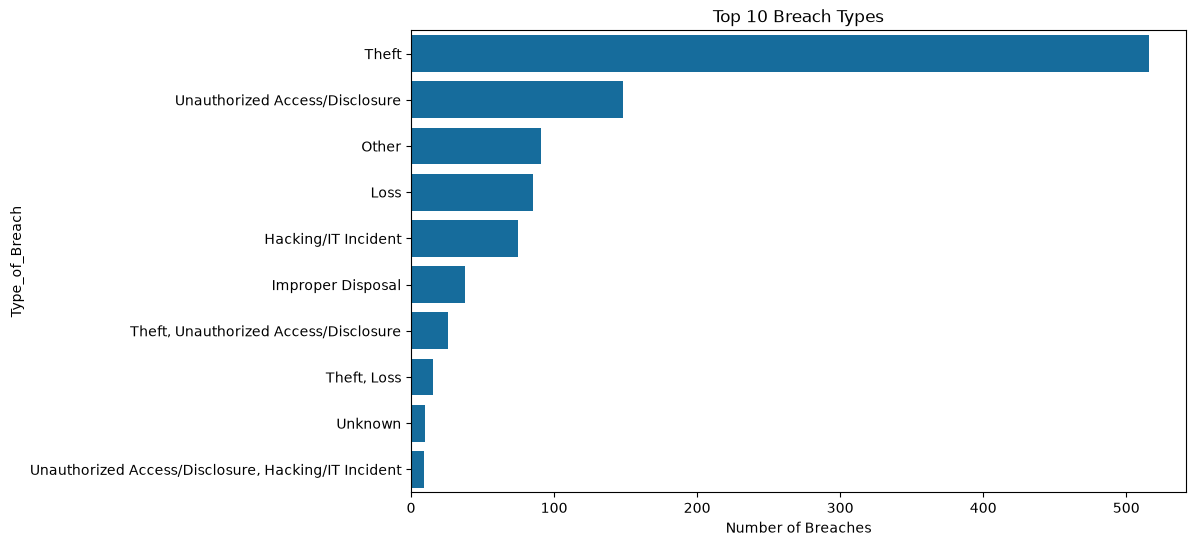

In [18]:
top_types = clean_df['Type_of_Breach'].value_counts().head(10)
plt.figure(figsize = (10,6))
sns.barplot(x = top_types.values, y = top_types.index, color ="#0072B2")
plt.title('Top 10 Breach Types')
plt.xlabel('Number of Breaches')
plt.show()

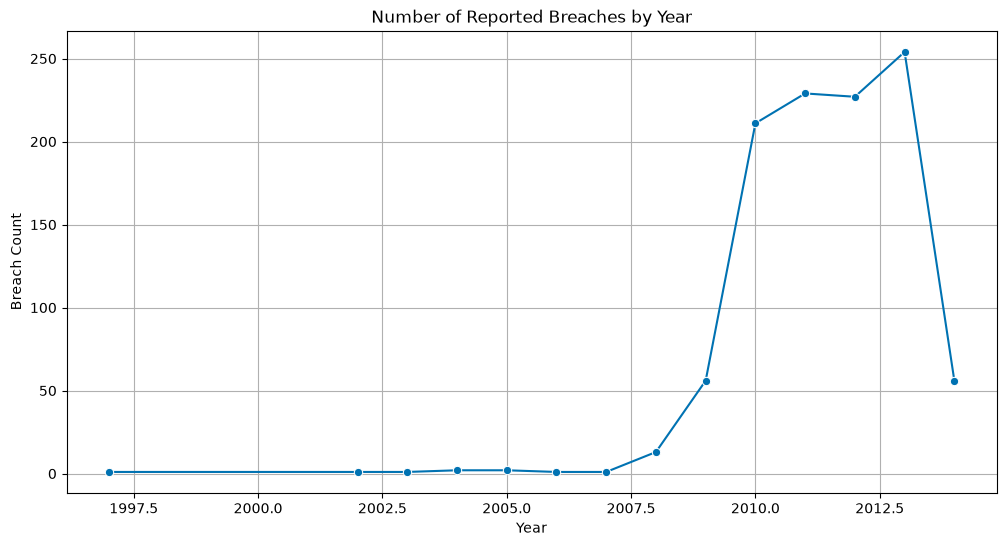

In [19]:
yearly = clean_df.groupby('year').size()
plt.figure(figsize = (12,6))
sns.lineplot(x = yearly.index, y = yearly.values, color="#0072B2", marker = 'o')
plt.title('Number of Reported Breaches by Year')
plt.xlabel('Year')
plt.ylabel('Breach Count')
plt.grid(True)
plt.show()

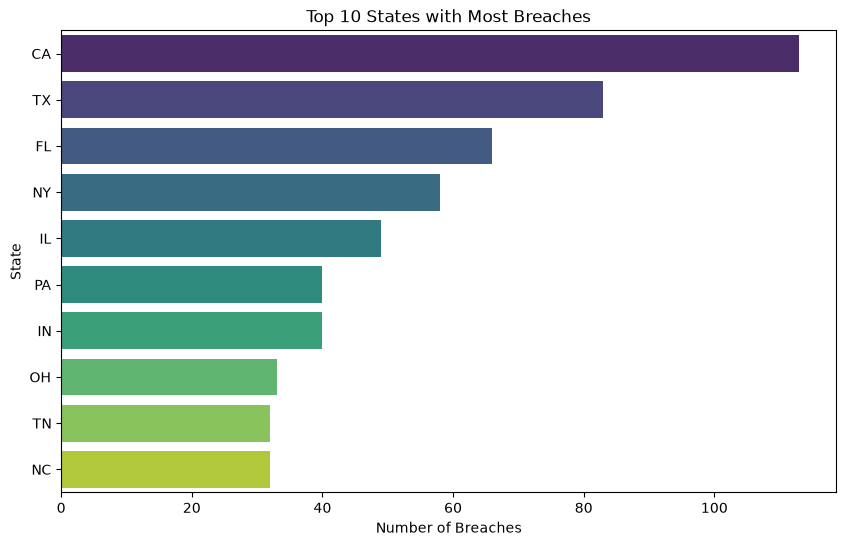

In [20]:
top_states = clean_df['State'].value_counts().head(10)
plt.figure(figsize = (10,6))
sns.barplot(
            x = top_states.values,
            y = top_states.index,
            hue = top_states.index,
            palette = 'viridis',
            legend = False
)
plt.title('Top 10 States with Most Breaches')
plt.xlabel('Number of Breaches')
plt.show()

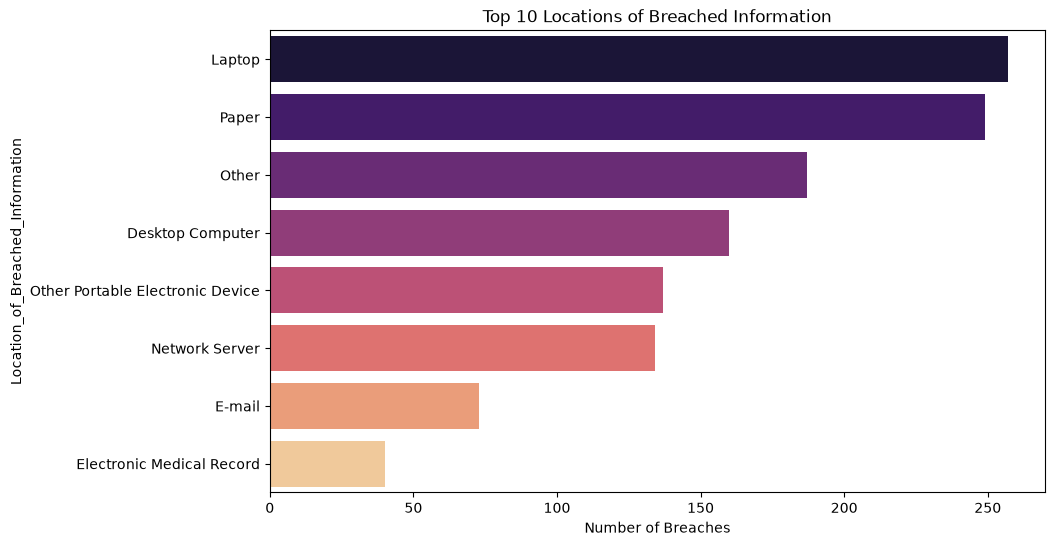

In [12]:
locations = clean_df['Location_of_Breached_Information'].str.split(',').explode().str.strip()
top_locs = locations.value_counts().head(10)
plt.figure(figsize = (10,6))
sns.barplot(x = top_locs.values, y = top_locs.index, hue = top_locs.index, palette='magma', legend=False)
plt.title('Top 10 Locations of Breached Information')
plt.xlabel('Number of Breaches')
plt.show()

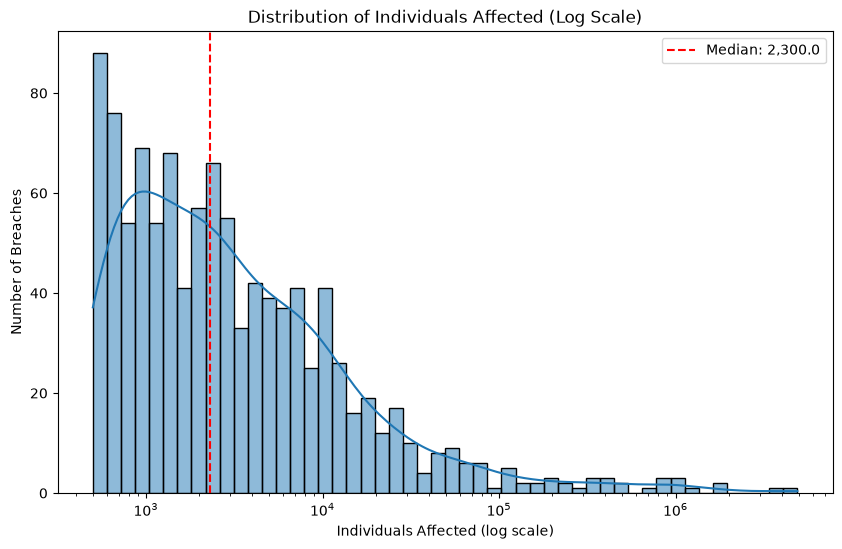

In [13]:
plt.figure(figsize = (10,6))
sns.histplot(clean_df['Individuals_Affected'], bins = 50, log_scale = True, kde = True)
plt.title('Distribution of Individuals Affected (Log Scale)')
plt.xlabel('Individuals Affected (log scale)')
plt.ylabel('Number of Breaches')
plt.axvline(clean_df['Individuals_Affected'].median(), color = 'red', linestyle = '--', label = f'Median: {clean_df["Individuals_Affected"].median():,}')
plt.legend()
plt.show()

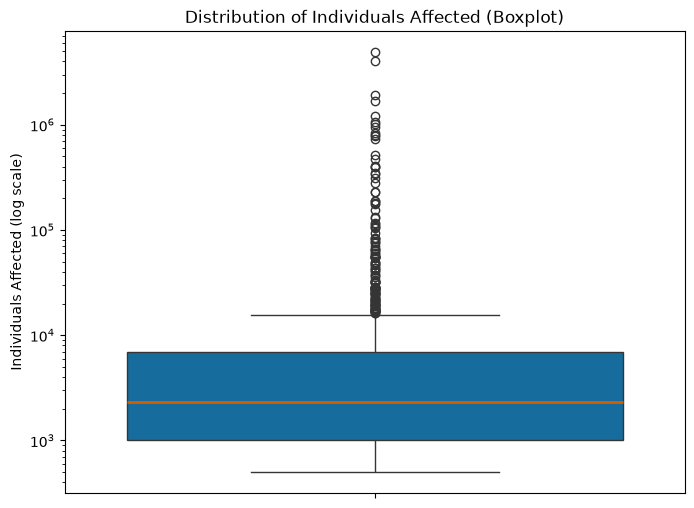

In [ ]:
plt.figure(figsize = (8,6))
sns.boxplot(
    y = clean_df['Individuals_Affected'], color = "#0072B2", medianprops = {"color": "#D55E00", "linewidth": 2})
plt.yscale('log')              
plt.title('Distribution of Individuals Affected (Boxplot)')
plt.ylabel('Individuals Affected (log scale)')
plt.show()